In [2]:
# install xgboost if required
# run this line once if xgboost is not installed
# %pip install xgboost

# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from xgboost import XGBClassifier

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

# load pharmacy sales dataset
df = pd.read_csv("global_pharmacy_sales_2020_2025_daily_dataset.csv")

print("dataset shape:", df.shape)
print(df.head())
print("\nmissing values:\n", df.isnull().sum())

dataset shape: (177990, 14)
         date  year  month  day         region    country category  \
0  2025-10-12  2025     10   12    Middle East        UAE  Chronic   
1  2020-09-15  2020      9   15     South Asia      India  Chronic   
2  2020-02-26  2020      2   26    Middle East        UAE  Vitamin   
3  2025-11-09  2025     11    9     South Asia  Sri Lanka  Chronic   
4  2022-04-04  2022      4    4  South America  Argentina  Chronic   

     medicine age_group  units_sold  unit_price  stock_level  \
0  Amlodipine      0-12         328       45.38         4774   
1  Amlodipine     26-45         371       75.49         4584   
2   Vitamin C      0-12         948       22.51         3934   
3  Amlodipine      0-12         275       63.29         4544   
4  Amlodipine     26-45         563       44.28         4284   

   expiry_days_remaining  covid_flag  
0                    466           0  
1                    181           1  
2                    556           1  
3         

In [3]:
# remove rows where the target is missing
df = df.dropna(subset=["units_sold"]).copy()

# create binary target: 1 = high demand, 0 = not high demand
high_demand_threshold = df["units_sold"].quantile(0.75)

df["high_demand"] = (
    df["units_sold"] >= high_demand_threshold
).astype(int)

# remove direct target information to prevent data leakage
X = df.drop(columns=[
    "units_sold",
    "high_demand",
    "date"
], errors="ignore")

y = df["high_demand"]

print("high-demand threshold:", high_demand_threshold)
print("\ntarget distribution:")
print(y.value_counts())
print("\ntarget proportions:")
print(y.value_counts(normalize=True).round(3))

high-demand threshold: 529.0

target distribution:
high_demand
0    133460
1     44530
Name: count, dtype: int64

target proportions:
high_demand
0    0.75
1    0.25
Name: proportion, dtype: float64


In [4]:
# split dataset before fitting preprocessing
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# create a separate validation set for early stopping
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.20,
    random_state=42,
    stratify=y_train_full
)

# identify numerical and categorical features
numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# handle missing numerical values
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# handle missing categories and encode text features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# combine preprocessing steps
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# fit preprocessing only on the training partition
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print("training rows:", X_train_processed.shape[0])
print("validation rows:", X_val_processed.shape[0])
print("testing rows:", X_test_processed.shape[0])
print("number of encoded features:", len(feature_names))

training rows: 113913
validation rows: 28479
testing rows: 35598
number of encoded features: 54


In [5]:
# calculate class imbalance weight
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("negative class:", negative_count)
print("positive class:", positive_count)
print("scale_pos_weight:", round(scale_pos_weight, 3))

# initialize xgboost classifier with regularization
xgb = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1,
    scale_pos_weight=scale_pos_weight,
    verbosity=0
)

negative class: 85414
positive class: 28499
scale_pos_weight: 2.997


In [6]:
# define hyperparameter search space
param_grid = {
    "n_estimators": [200, 400, 600],
    "max_depth": [3, 4, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "min_child_weight": [1, 3, 5],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.7, 0.85, 1.0],
    "gamma": [0, 0.1, 0.3],
    "reg_alpha": [0, 0.1, 1.0],
    "reg_lambda": [1, 5, 10]
}

# stratified cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# randomized hyperparameter search
search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_grid,
    n_iter=15,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

# train and tune using training data only
search.fit(X_train_processed, y_train)

print("best parameters:")
print(search.best_params_)

print("\nbest cross-validation F1-score:")
print(round(search.best_score_, 4))

Fitting 3 folds for each of 15 candidates, totalling 45 fits
best parameters:
{'subsample': 0.85, 'reg_lambda': 5, 'reg_alpha': 0.1, 'n_estimators': 400, 'min_child_weight': 1, 'max_depth': 8, 'learning_rate': 0.01, 'gamma': 0, 'colsample_bytree': 0.7}

best cross-validation F1-score:
0.7744


In [7]:
# create optimized model with early stopping
best_params = search.best_params_.copy()

best_params.update({
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "tree_method": "hist",
    "scale_pos_weight": scale_pos_weight,
    "early_stopping_rounds": 30,
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": 0
})

best_xgb = XGBClassifier(**best_params)

# train using a separate validation set
best_xgb.fit(
    X_train_processed,
    y_train,
    eval_set=[(X_val_processed, y_val)],
    verbose=False
)

print("best iteration:", best_xgb.best_iteration)
print("best validation log loss:",
      round(best_xgb.best_score, 4))

best iteration: 399
best validation log loss: 0.2522


accuracy: 0.8649
precision: 0.6684
recall: 0.9128
f1-score: 0.7717
roc-auc: 0.9612

classification report:

                 precision    recall  f1-score   support

Not high demand       0.97      0.85      0.90     26692
    High demand       0.67      0.91      0.77      8906

       accuracy                           0.86     35598
      macro avg       0.82      0.88      0.84     35598
   weighted avg       0.89      0.86      0.87     35598



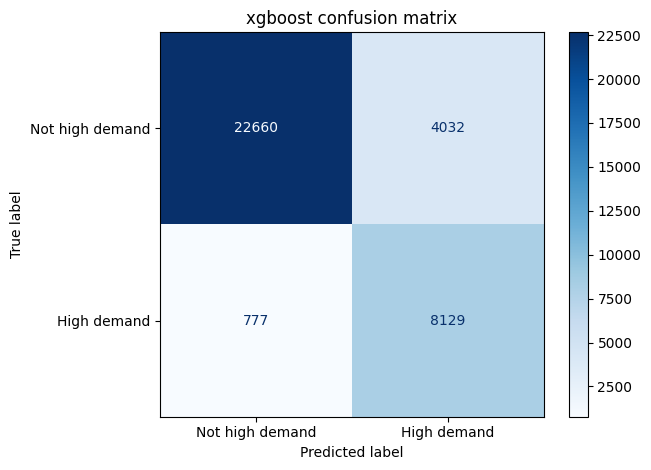

In [8]:
# predict class labels and probabilities
y_pred = best_xgb.predict(X_test_processed)
y_prob = best_xgb.predict_proba(X_test_processed)[:, 1]

# calculate evaluation metrics
print("accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("f1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("roc-auc:", round(roc_auc_score(y_test, y_prob), 4))

print("\nclassification report:\n")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not high demand", "High demand"],
    zero_division=0
))

# display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Not high demand", "High demand"],
    cmap="Blues"
)

plt.title("xgboost confusion matrix")
plt.tight_layout()
plt.show()

                   feature  importance
          num__stock_level    0.415638
           num__covid_flag    0.215694
                 num__year    0.142720
                num__month    0.091988
      cat__country_Nigeria    0.003290
 cat__region_North America    0.003172
          cat__country_USA    0.003157
   cat__country_Bangladesh    0.003089
           num__unit_price    0.003071
        cat__region_Africa    0.003014
                  num__day    0.002998
 cat__category_Antipyretic    0.002970
 cat__region_South America    0.002949
cat__medicine_Multivitamin    0.002949
      cat__country_Germany    0.002930


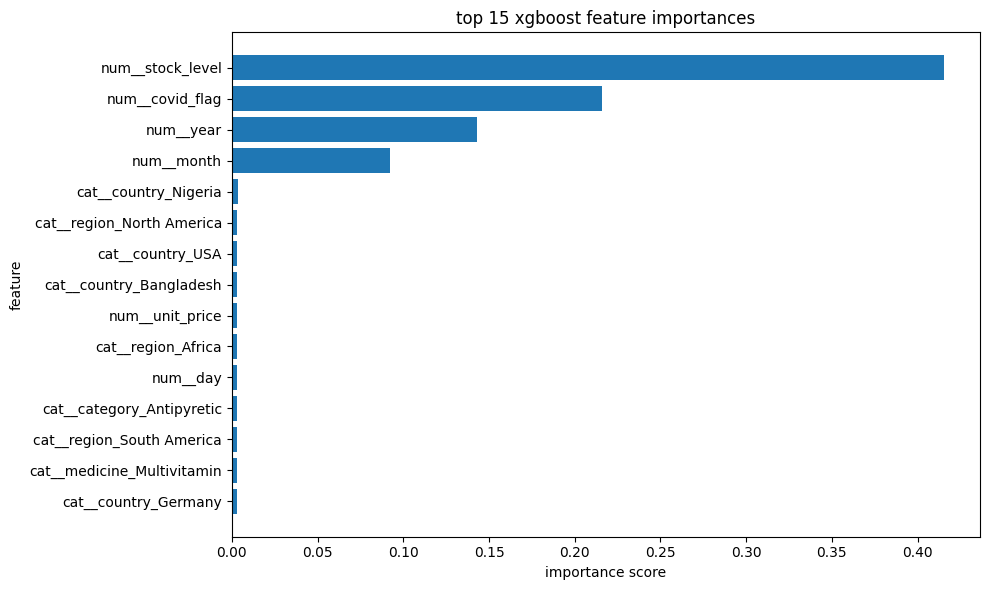

In [9]:
# extract importance scores from the optimized model
importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": best_xgb.feature_importances_
})

# display the 15 most important features
importance_df = importance_df.sort_values(
    "importance", ascending=False
).head(15)

print(importance_df.to_string(index=False))

# visualize important features
plt.figure(figsize=(10, 6))
plt.barh(
    importance_df["feature"][::-1],
    importance_df["importance"][::-1]
)

plt.xlabel("importance score")
plt.ylabel("feature")
plt.title("top 15 xgboost feature importances")
plt.tight_layout()
plt.show()

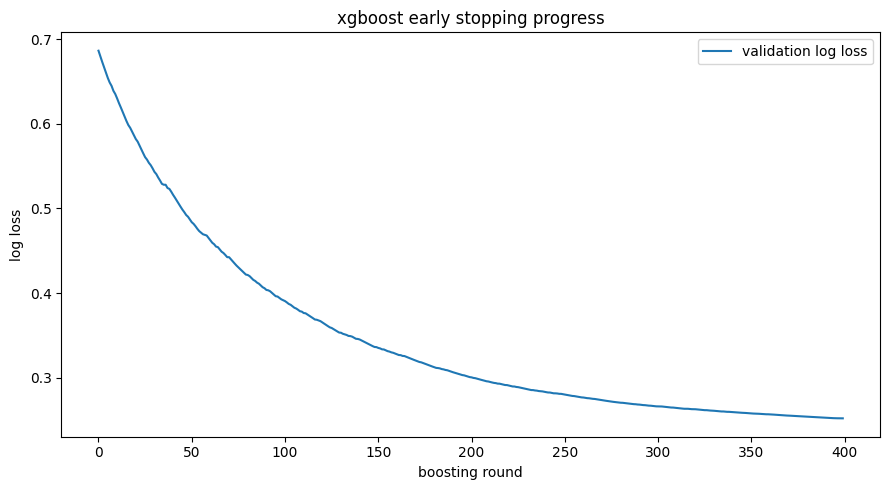

In [10]:
# visualize log loss across boosting rounds
eval_results = best_xgb.evals_result()

plt.figure(figsize=(9, 5))

plt.plot(
    eval_results["validation_0"]["logloss"],
    label="validation log loss"
)

plt.xlabel("boosting round")
plt.ylabel("log loss")
plt.title("xgboost early stopping progress")
plt.legend()
plt.tight_layout()
plt.show()